<a href="https://colab.research.google.com/github/Biko-alt/COMP30307-AI/blob/main/lab09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Lab 9: Support Vector Machines (SVM) with World Population Data

**Objective**: Use SVM to classify countries into population size categories based on demographic and geographic features.

**Dataset**: World Population Dataset from Kaggle  
Link: https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset

**Theory**:
- Support Vector Machines (SVM) are supervised learning models used for classification and regression.
- SVM finds the optimal hyperplane that separates classes with the maximum margin.
- It can use kernel functions to handle non-linear boundaries.
- Feature scaling is essential because SVM relies on distance calculations.
- Common kernels include linear, polynomial, and RBF (radial basis function).

In [20]:
# 📦 Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 📥 Step 2: Load the dataset
This dataset includes country-level features such as population, area, density, growth rate, and fertility rate.

In [21]:
# Load the dataset
url = "https://raw.githubusercontent.com/datasets/population/master/data/population.csv"
# Alternatively, use the raw link from your dataset source
try:
    df = pd.read_csv(url)
except Exception:
    # Fallback to another public world population source if the previous one is unavailable
    url = "https://raw.githubusercontent.com/datasets/population/main/data/population.csv"
    df = pd.read_csv(url)

df.head()

,Country Name,Country Code,Year,Value
0,Aruba,ABW,1960,54922
1,Aruba,ABW,1961,55578
2,Aruba,ABW,1962,56320
3,Aruba,ABW,1963,57002
4,Aruba,ABW,1964,57619


## 🧠 Step 3: Create population categories
We'll classify countries into three categories based on population size:
- Low: < 10 million
- Medium: 10–100 million
- High: > 100 million

In [23]:
# The loaded dataset has a 'Value' column representing population and a 'Year' column.
# We first filter for the year 2022 to get a single population value per country.
df_2022 = df[df['Year'] == 2022].copy()

# Convert population Value to float
df_2022['Value'] = df_2022['Value'].astype(float)

# Create population category including Low, Medium, and High
def categorize(pop):
    if pop < 1e7:       # < 10 million
        return 'Low'
    elif pop < 1e8:     # 10 million to 100 million
        return 'Medium'
    else:               # > 100 million
        return 'High'

df_2022['Pop_Category'] = df_2022['Value'].apply(categorize)
df_2022['Pop_Label'] = df_2022['Pop_Category'].map({'Low': 0, 'Medium': 1, 'High': 2})

# Reassign df to use our processed 2022 data
df = df_2022

In [ ]:
df.head()

,Rank,CCA3,Country/Territory,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage,Pop_Category,Pop_Label
0,36,AFG,Afghanistan,Kabul,Asia,41128771.0,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,1.0257,0.52,Medium,1
1,138,ALB,Albania,Tirana,Europe,2842321.0,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.9957,0.04,Low,0
2,34,DZA,Algeria,Algiers,Africa,44903225.0,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,1.0164,0.56,Medium,1
3,213,ASM,American Samoa,Pago Pago,Oceania,44273.0,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.9831,0.00,Low,0
4,203,AND,Andorra,Andorra la Vella,Europe,79824.0,77700,71746,71519,66097,53569,35611,19860,468,170.5641,1.0100,0.00,Low,0


## 🧹 Step 4: Preprocess the data
We select relevant features and scale them for SVM.

In [27]:
# Select available features from the current dataset
features = ['Year', 'Value']
X = df[features]
y = df['Pop_Label']

# Handle missing values
X = X.fillna(X.mean())

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.4, random_state=42)

## 🧪 Step 5: Train the SVM classifier
We use the RBF kernel and evaluate performance.

In [28]:
# Train SVM model
# kernel='linear', 'poly', or 'sigmoid' , 'rbf'

svm = SVC(kernel='sigmoid', C=1.0, gamma='scale')
svm.fit(X_train, y_train)

# Predict
y_pred = svm.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.6415094339622641

Classification Report:
               precision    recall  f1-score   support

           0       0.57      1.00      0.73        51
           1       0.00      0.00      0.00        30
           2       1.00      0.68      0.81        25

    accuracy                           0.64       106
   macro avg       0.52      0.56      0.51       106
weighted avg       0.51      0.64      0.54       106



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## 📊 Step 6: Visualize the confusion matrix
This shows how well the model distinguishes between population categories.

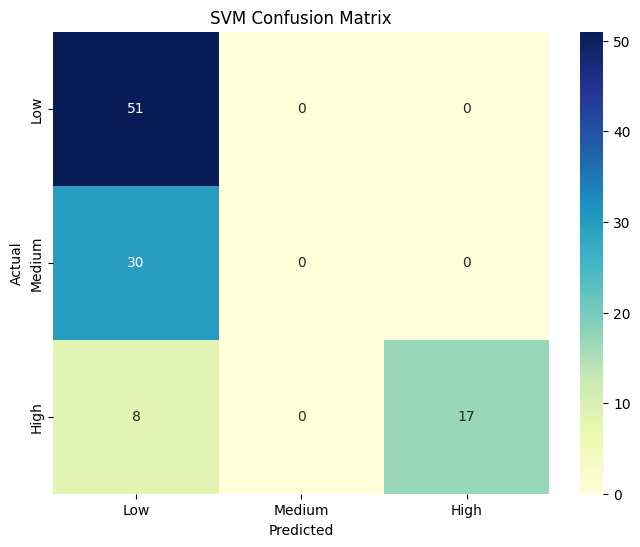

In [29]:
# Confusion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=['Low','Medium','High'], yticklabels=['Low','Medium','High'])
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 🔍 Step 7: Try different kernel functions
Try changing `kernel='linear'`, `'poly'`, or `'sigmoid'` and observe how performance changes.

## 📝 Reflection Questions

1. What does the SVM decision boundary represent in this context?
SVM decision boundary is a multi-dimensional hyperplane that optimally segregates countries into population size categories using geographical and demographic factors such as area, density, and growth rate.
2. How does the choice of kernel affect classification?
The selection of a kernel dictates how the feature space will be mapped. Linear kernels perform satisfactorily on linearly separable data sets, whereas non-linear kernels such as RBF or Polynomial map data into a higher dimensional feature space.
3. Why is feature scaling critical for SVM?
Feature scaling is necessary since the distance measurements and margin maximization play a crucial role in SVM. If feature scaling was not done, then features with wider ranges of values would influence the objective function more than those with narrower ranges.
4. How could this model be used to support global development or resource planning?
Both governments and global organizations can apply this system of classification when new regions begin to develop, depending on their demographic changes, enabling efficient investment into their infrastructure development, provision of humanitarian help, and resource distribution planning.